In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ppscore as pps
from sklearn.manifold import TSNE
import hdbscan
sns.set_theme(style="whitegrid")

In [ ]:
# Load cleaned dataset
df = pd.read_csv("../Data/Credit_Cleaned.csv")

In [ ]:
# Basic overview
print("Dataset shape:", df.shape)
display(df.head())

In [37]:
display(df.info())
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   income           400 non-null    float64
 1   credit_limit     400 non-null    int64  
 2   credit_rating    400 non-null    int64  
 3   num_cards        400 non-null    int64  
 4   age              400 non-null    int64  
 5   education_years  400 non-null    int64  
 6   is_homeowner     400 non-null    int64  
 7   is_student       400 non-null    int64  
 8   is_married       400 non-null    int64  
 9   region           400 non-null    str    
 10  balance          400 non-null    int64  
dtypes: float64(1), int64(9), str(1)
memory usage: 34.5 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
income,400.0,NaN,NaN,NaN,45.218885,35.244273,10.354,21.00725,33.1155,57.47075,186.634
credit_limit,400.0,NaN,NaN,NaN,4735.6,2308.198848,855.0,3088.0,4622.5,5872.75,13913.0
credit_rating,400.0,NaN,NaN,NaN,354.94,154.724143,93.0,247.25,344.0,437.25,982.0
num_cards,400.0,NaN,NaN,NaN,2.9575,1.371275,1.0,2.0,3.0,4.0,9.0
age,400.0,NaN,NaN,NaN,55.6675,17.249807,23.0,41.75,56.0,70.0,98.0
education_years,400.0,NaN,NaN,NaN,13.45,3.125207,5.0,11.0,14.0,16.0,20.0
is_homeowner,400.0,NaN,NaN,NaN,0.5175,0.500319,0.0,0.0,1.0,1.0,1.0
is_student,400.0,NaN,NaN,NaN,0.1,0.300376,0.0,0.0,0.0,0.0,1.0
is_married,400.0,NaN,NaN,NaN,0.6125,0.48779,0.0,0.0,1.0,1.0,1.0
region,400,3,south,199,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
# Missing values
print(df.isnull().sum())

# Duplicates
print("Duplicate rows:", df.duplicated().sum())

income             0
credit_limit       0
credit_rating      0
num_cards          0
age                0
education_years    0
is_homeowner       0
is_student         0
is_married         0
region             0
balance            0
dtype: int64
Duplicate rows: 0


In [28]:
# Select only numeric columns for correlation and distribution analysis
numeric_df = df.select_dtypes(include=np.number)

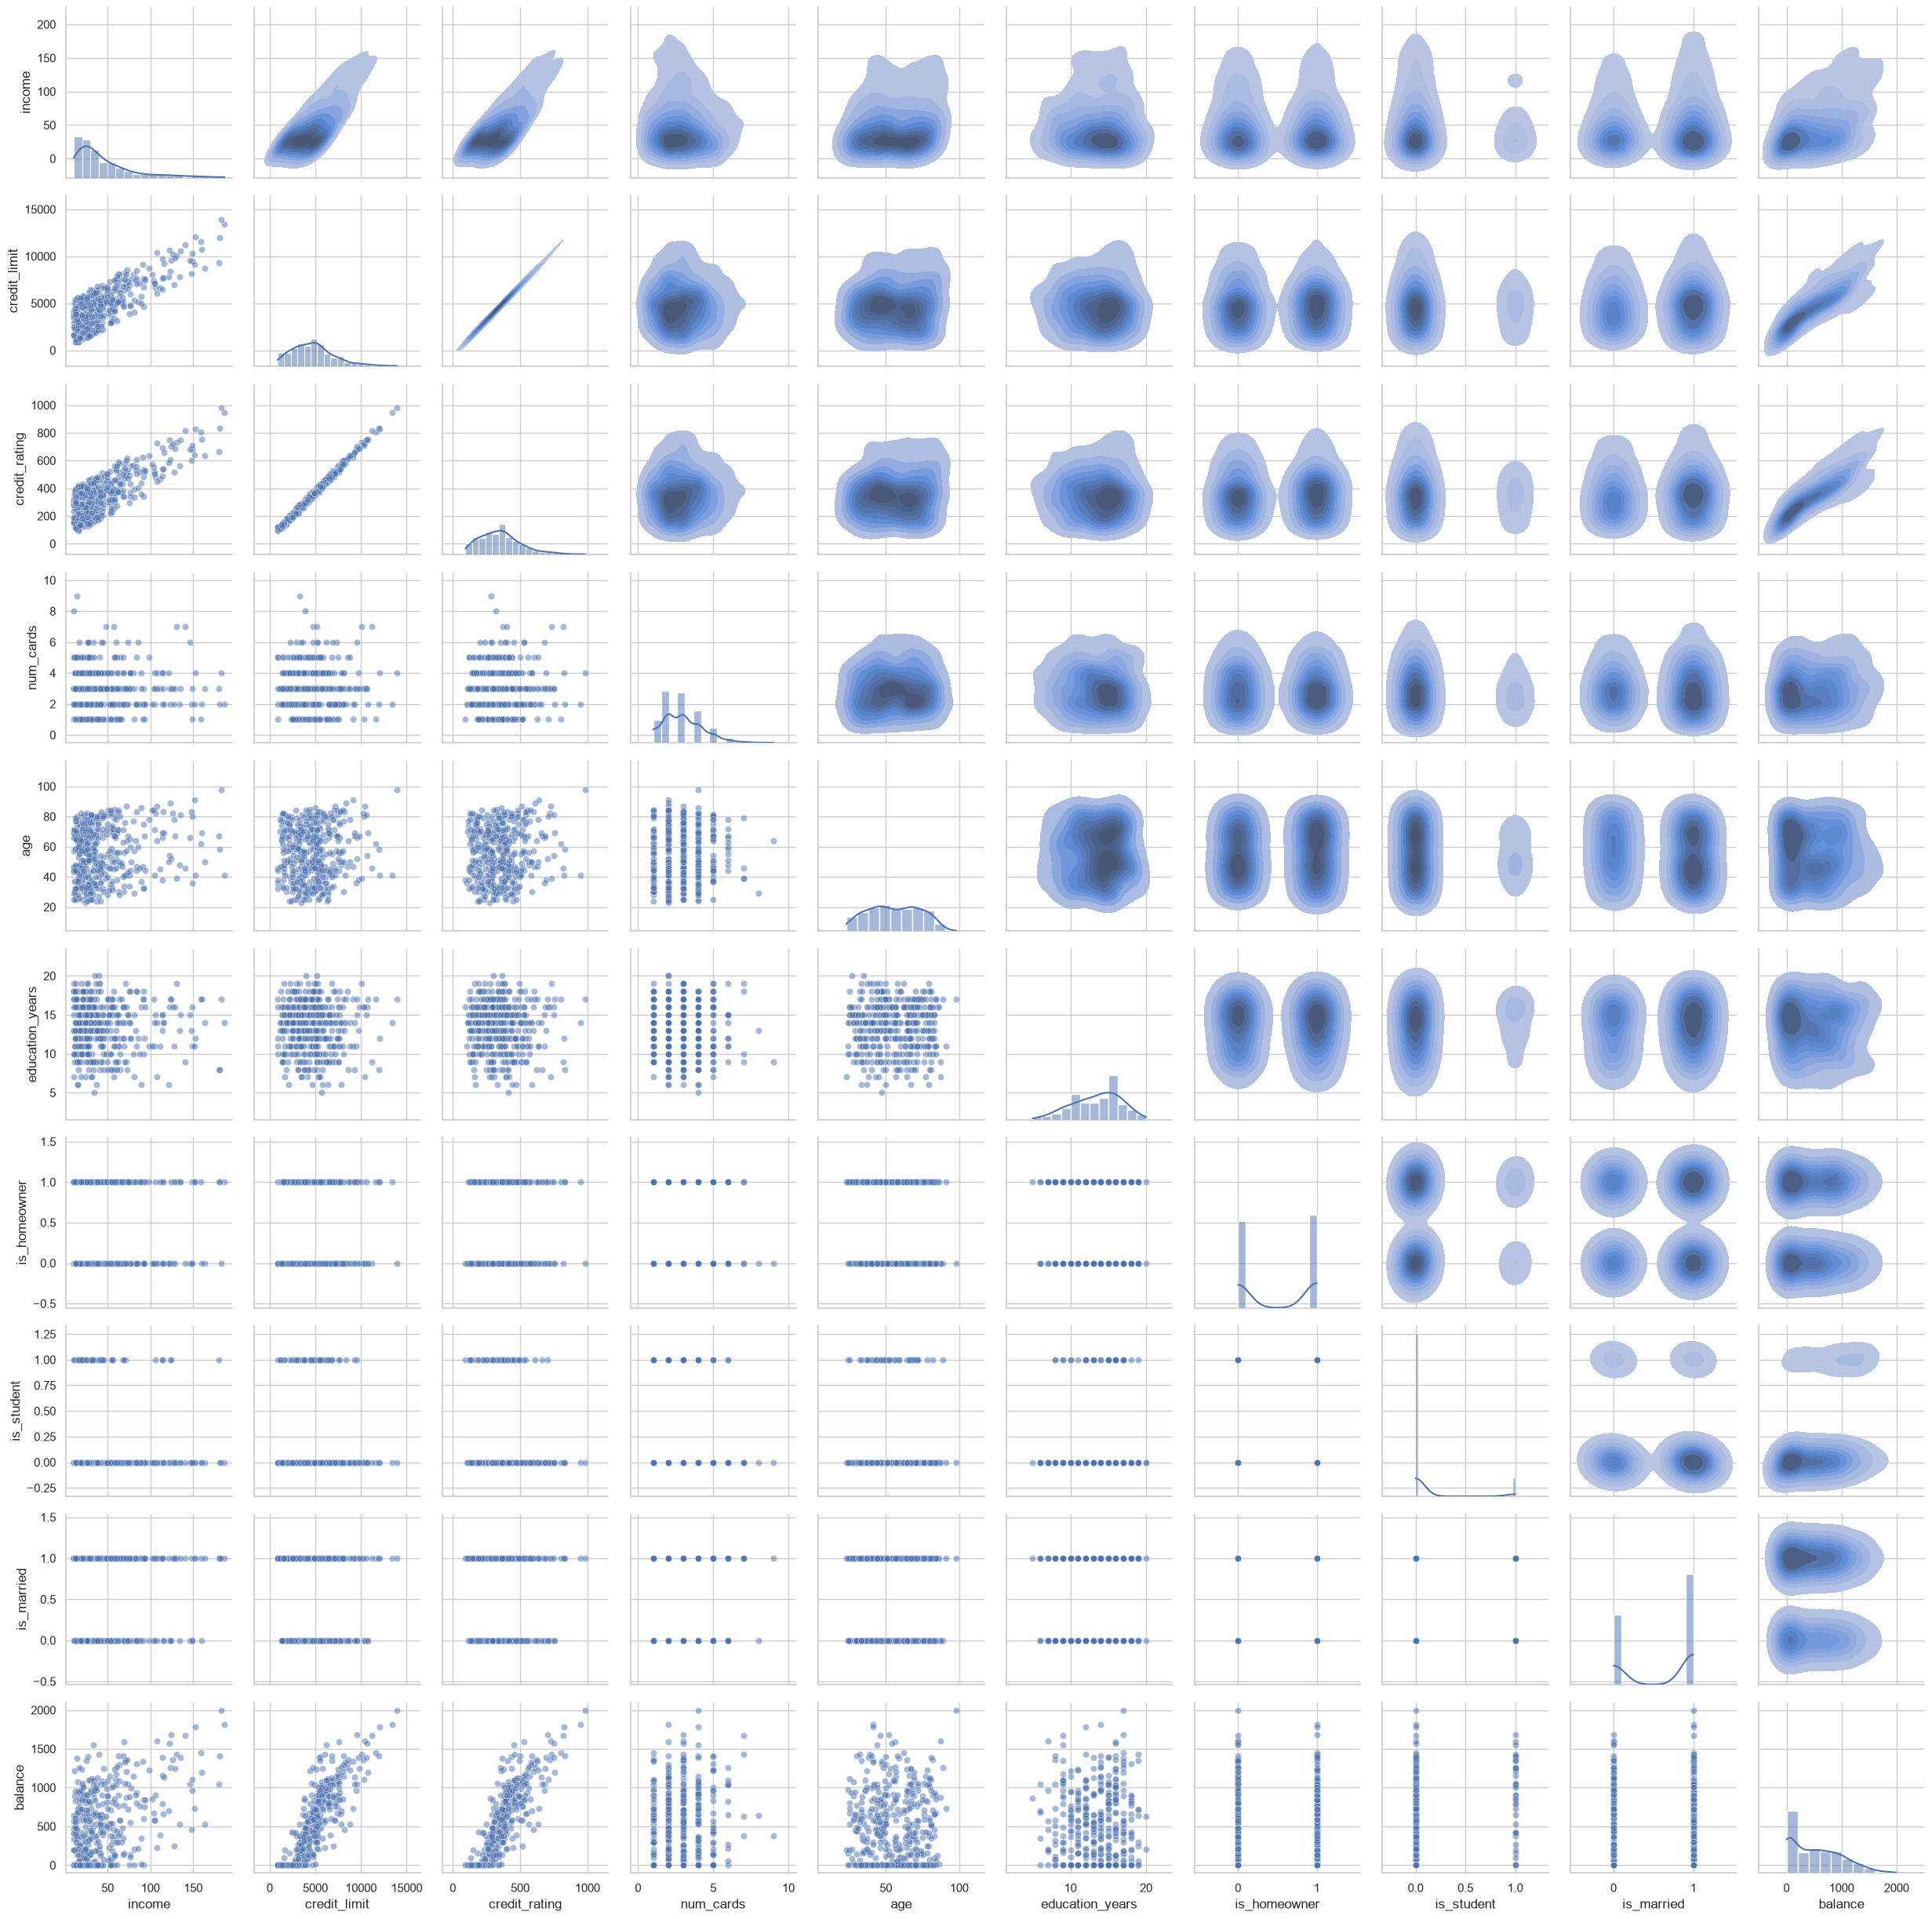

In [29]:
# Initialize the PairGrid with the numeric data
g = sns.PairGrid(numeric_df)

# Map different plot types to different sections of the grid
g.map_diag(sns.histplot, kde=True)      # Diagonal: Histograms with KDE curves
g.map_lower(sns.scatterplot, alpha=0.5) # Lower triangle: Scatter plots
g.map_upper(sns.kdeplot, fill=True)     # Upper triangle: KDE heatmaps

# Display the final plot
plt.show()

In [30]:
pearson = numeric_df.corr(method="pearson")
spearman = numeric_df.corr(method="spearman")

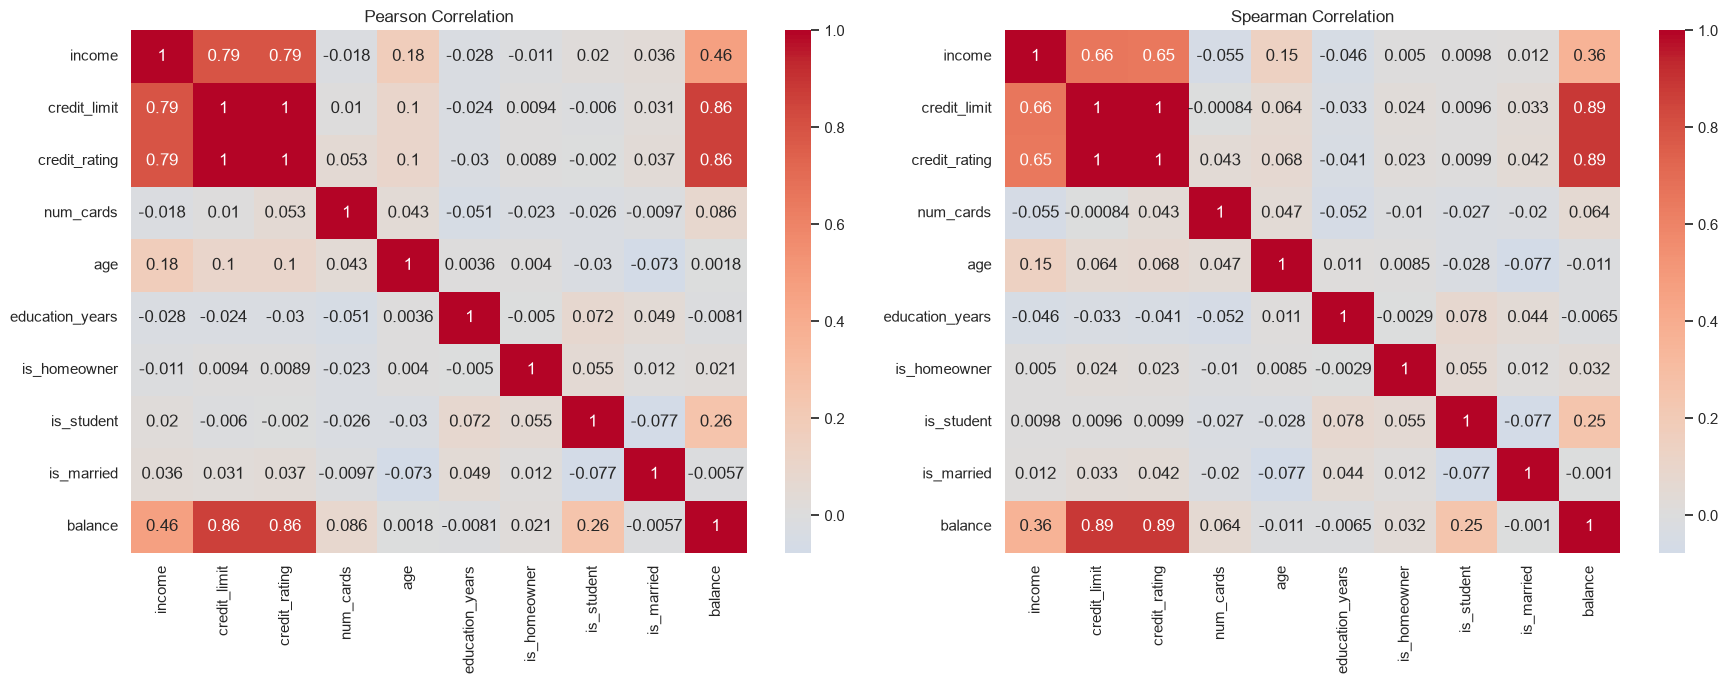

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    pearson, annot=True, cmap="coolwarm",
    center=0, ax=axes[0]
)
axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman, annot=True, cmap="coolwarm",
    center=0, ax=axes[1]
)
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

In [32]:
pps_matrix = pps.matrix(df)

pps_pivot = pps_matrix.pivot(
    index="x",
    columns="y",
    values="ppscore"
)

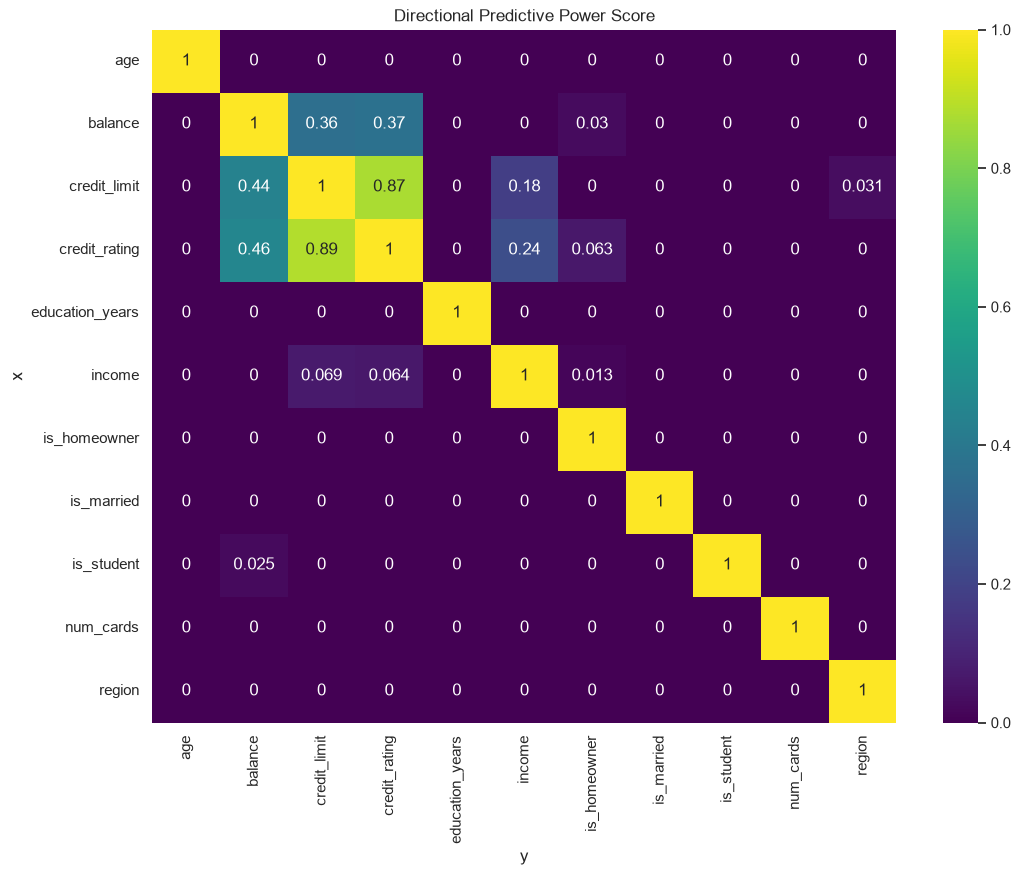

In [33]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    pps_pivot,
    annot=True,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.title("Directional Predictive Power Score")
plt.show()

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Copy numeric data and standardize it
X_numeric = numeric_df.copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

# Apply PCA, reducing the dimensions down to 3 components
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

In [35]:
# Check how much variance each principal component explains
print("Explained variance per component:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance per component: [0.34314925 0.11656117 0.11003677]
Total explained variance: 0.569747193091348


In [40]:
# Initialize t-SNE (using max_iter instead of n_iter)
tsne = TSNE(
    n_components=3,
    perplexity=30,
    random_state=42,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_scaled)
print("t-SNE embedding shape:", X_tsne.shape)

t-SNE embedding shape: (400, 3)


In [41]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=5
)

cluster_labels = clusterer.fit_predict(X_scaled)

df["cluster"] = cluster_labels

print(df["cluster"].value_counts())

cluster
 1    356
 0     38
-1      6
Name: count, dtype: int64


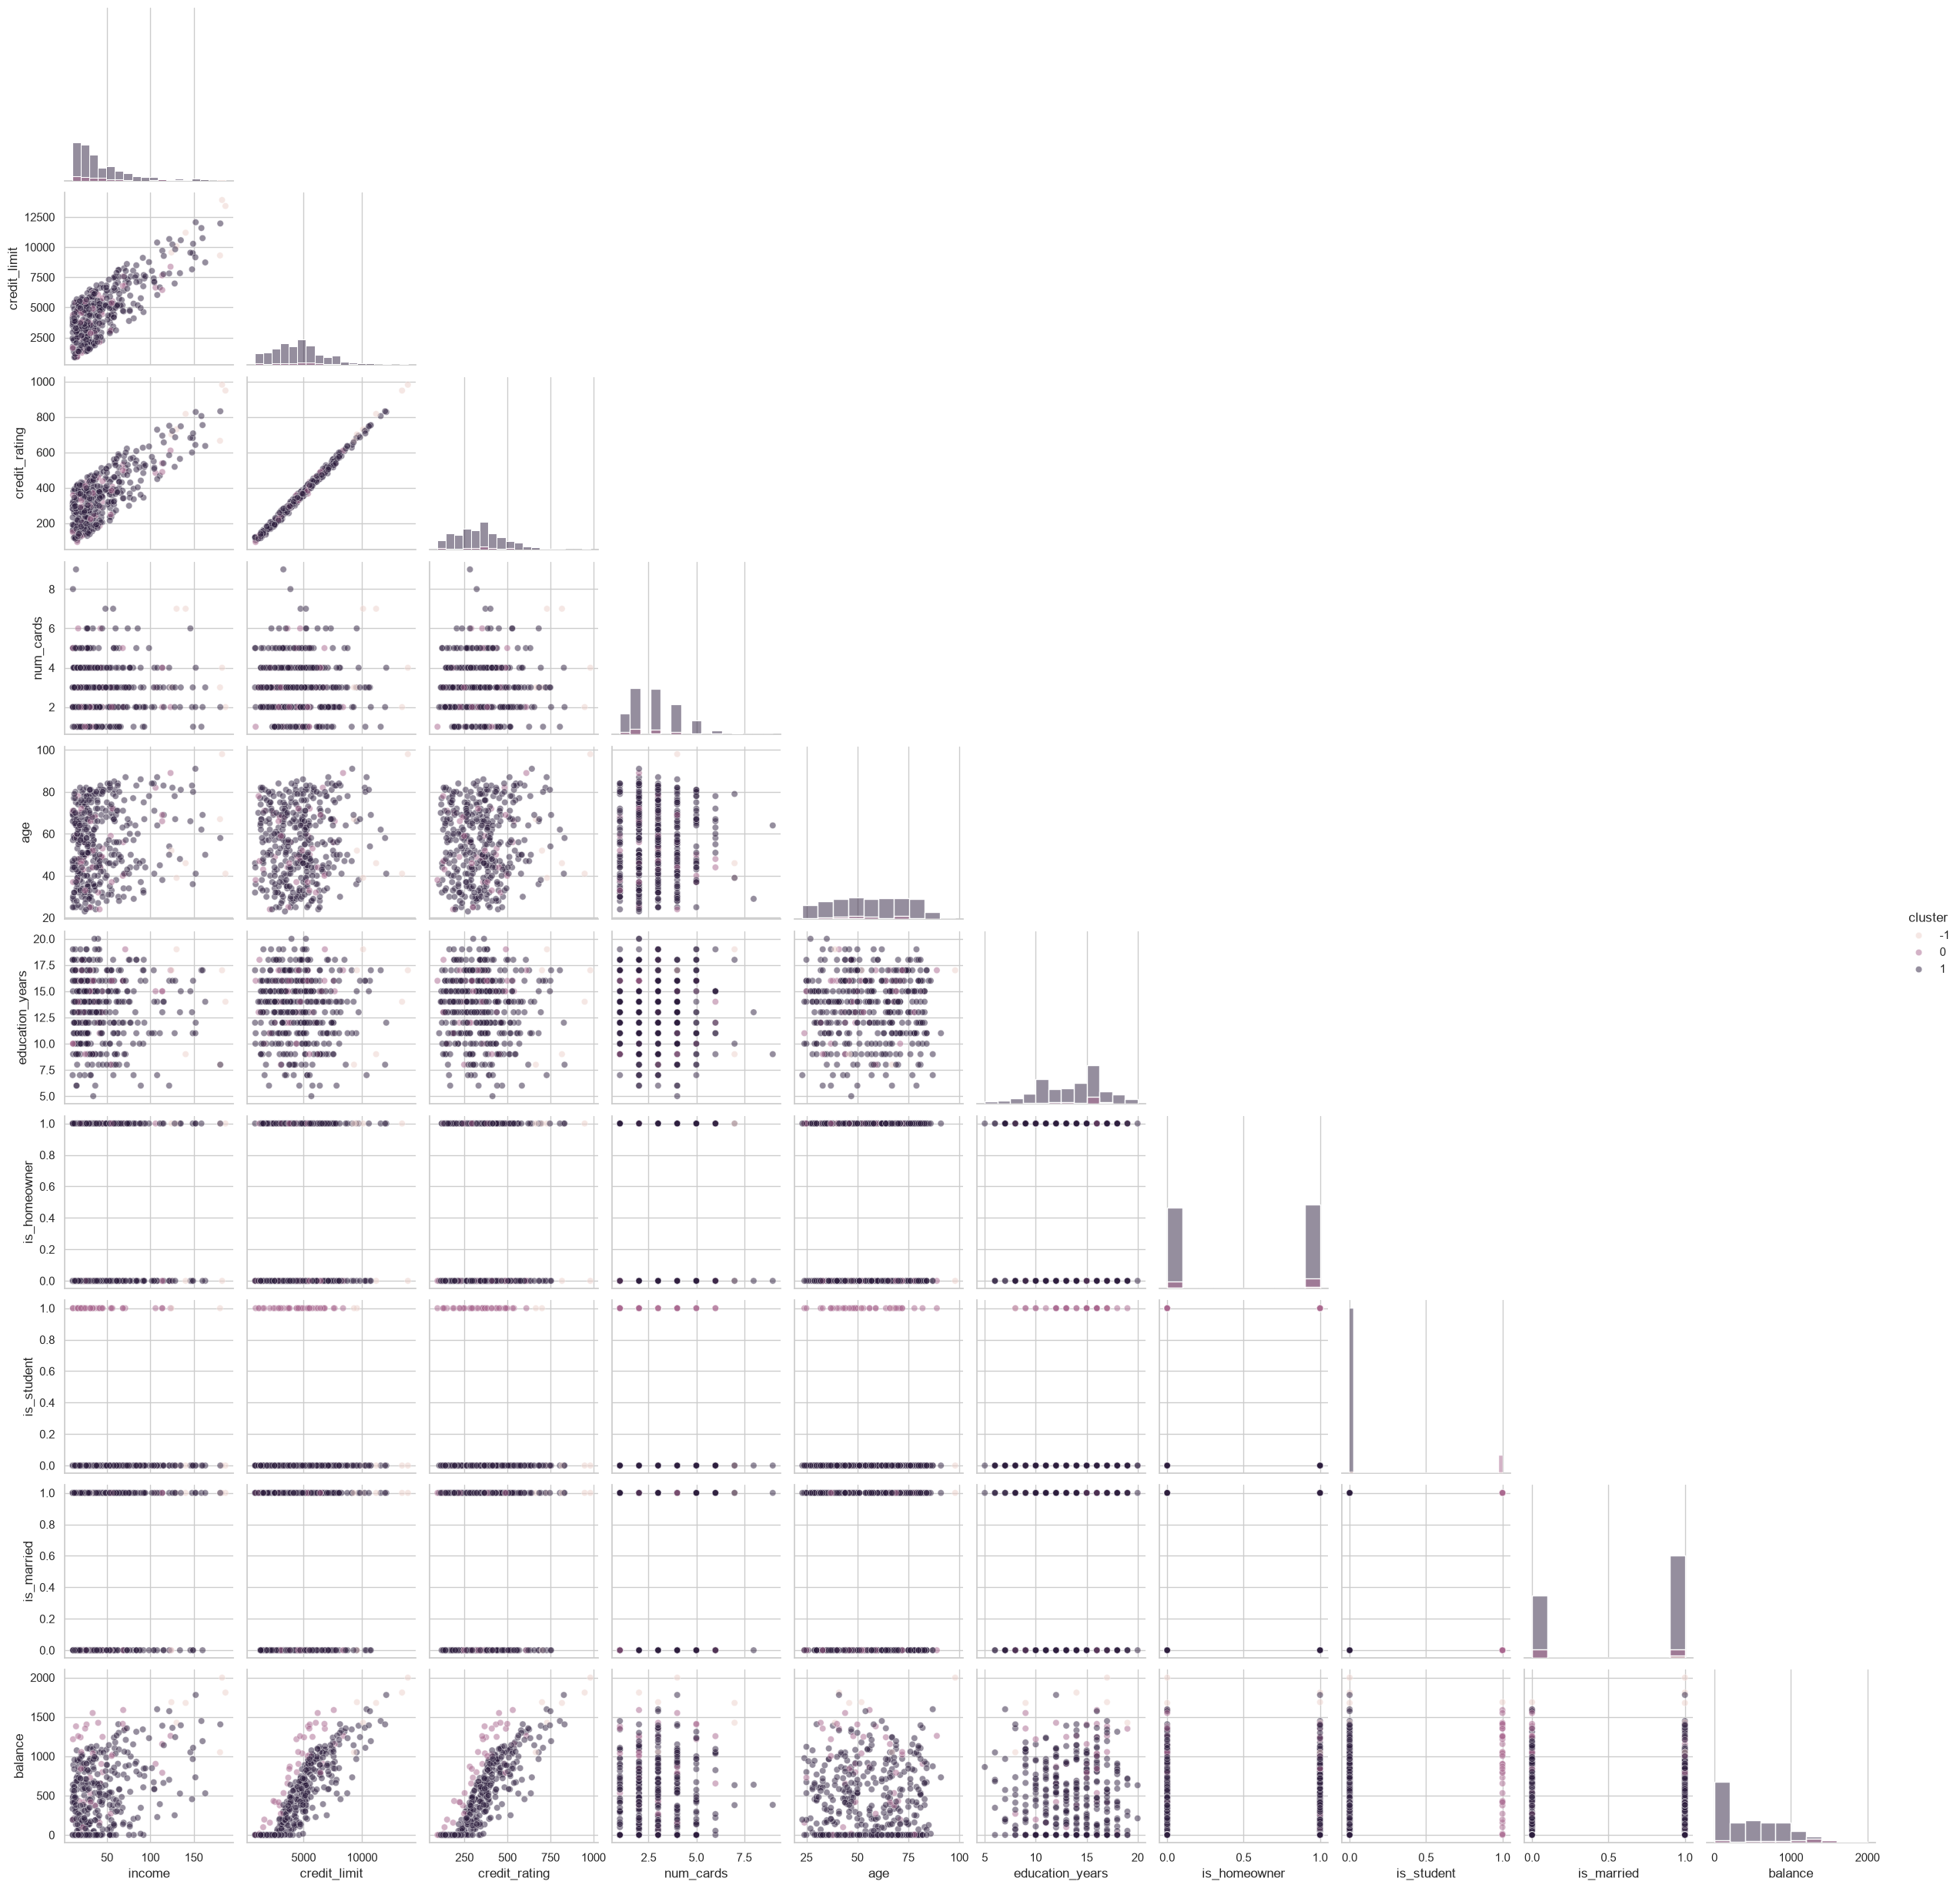

In [42]:
g = sns.pairplot(
    df,
    vars=numeric_df.columns,
    hue="cluster",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5}
)

plt.show()